In [1]:
import torch

torch.cuda.is_available()

True

# 0. Prepare Library

In [ ]:
!pip install pygame-ce

# 1. Init Game Environment

In [2]:
import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# Thêm thư mục hiện tại vào sys.path để import được src/
sys.path.append(os.path.abspath("."))

from src.flappy_bird import FlappyBird
from src.utils import pre_processing

# Khởi tạo môi trường
game_state = FlappyBird()
print("FlappyBird environment initialized successfully!")
print(f"Original screen size: {game_state.screen_width} x {game_state.screen_height}")

pygame-ce 2.5.8 (SDL 2.32.10, Python 3.14.4)
FlappyBird environment initialized successfully!
Original screen size: 288 x 512


# 2. Inital Frame & Image Preprocessing

In [8]:
# 1. Step with action 0 (idle)
raw_image, reward, terminal = game_state.next_frame(0)
print(f"Raw RGB image: shape = {raw_image.shape}, dtype = {raw_image.dtype}")
print(f"Initial reward: {reward}, Terminal (game over?): {terminal}")

# 2. Crop floor area and preprocess image to 84x84 binary format
cropped_image = raw_image[:game_state.screen_width, :int(game_state.base_y)]
processed_frame = pre_processing(cropped_image, 84, 84)  # shape: (1, 84, 84)
frame_tensor = torch.from_numpy(processed_frame)

# 3. Build initial State: Stack 4 identical frames
# tuple(frame_tensor for _ in range(4)) concatenates 4 tensors [1, 84, 84] -> [4, 84, 84]
# [None, :, :, :] adds batch dimension -> shape: [1, 4, 84, 84]
state = torch.cat(tuple(frame_tensor for _ in range(4)))[None, :, :, :]

print(f"State fed into Model: shape = {state.shape}")
print("-> 1: Batch size | 4: Stacked frames | 84x84: Height x Width")

Raw RGB image: shape = (288, 512, 3), dtype = uint8
Initial reward: 0.1, Terminal (game over?): False
State fed into Model: shape = torch.Size([1, 4, 84, 84])
-> 1: Batch size | 4: Stacked frames | 84x84: Height x Width


In [9]:
from PIL import Image

raw = Image.fromarray(raw_image)
crop = Image.fromarray(cropped_image)
process = Image.fromarray(processed_frame[0])

Raw image


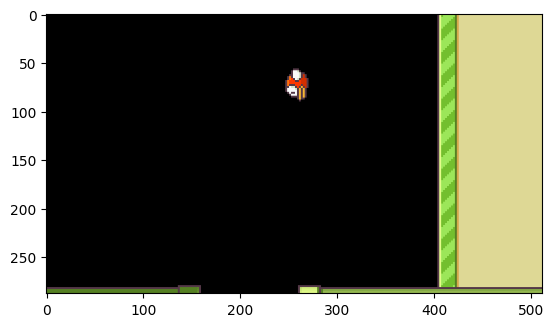

In [10]:
print(f'Raw image')
plt.imshow(raw, cmap='gray')

Crop image


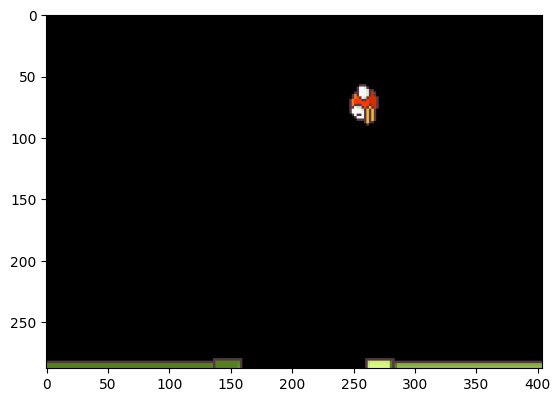

In [11]:
print(f'Crop image')
plt.imshow(crop, cmap='gray')

Process image


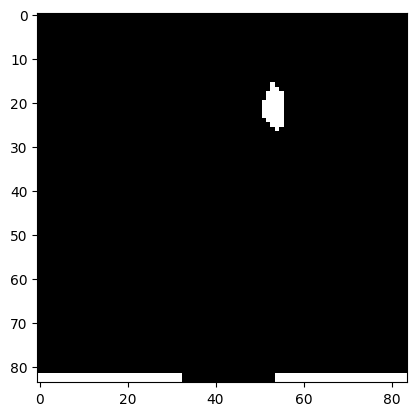

In [12]:
print(f'Process image')
plt.imshow(processed_frame[0], cmap='gray')

# 3. Action & State Transition

In [13]:
action = 1  # 1 = Flap, 0 = Idle
next_raw_image, reward, terminal = game_state.next_frame(action)

# Preprocess new frame
next_cropped = next_raw_image[:game_state.screen_width, :int(game_state.base_y)]
next_frame = pre_processing(next_cropped, 84, 84)
next_frame_tensor = torch.from_numpy(next_frame)

# Sliding window transition: state[0, 1:, :, :] extracts last 3 frames, then concats new frame
next_state = torch.cat((state[0, 1:, :, :], next_frame_tensor))[None, :, :, :]

print(f"Executed action: {action}")
print(f"Received reward: {reward}")
print(f"Game over flag (terminal): {terminal}")
print(f"Next State shape: {next_state.shape}")

# Update current state
state = next_state

Executed action: 1
Received reward: 0.1
Game over flag (terminal): False
Next State shape: torch.Size([1, 4, 84, 84])


In [14]:
from PIL import Image

raw = Image.fromarray(next_raw_image)
crop = Image.fromarray(next_cropped)
process = Image.fromarray(processed_frame[0])

Raw image


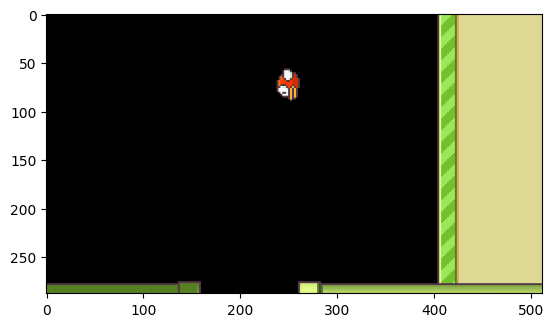

In [15]:
print(f'Raw image')
plt.imshow(raw, cmap='gray')

Crop image


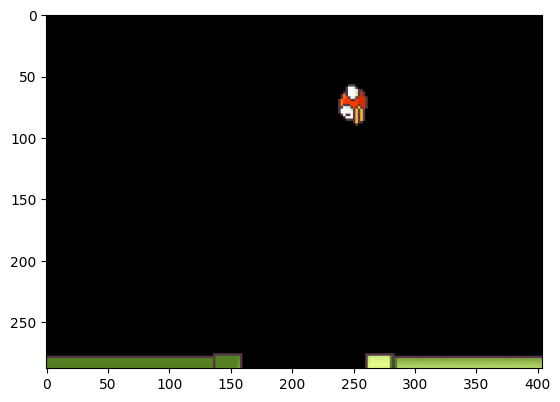

In [16]:
print(f'Crop image')
plt.imshow(crop, cmap='gray')

Process image


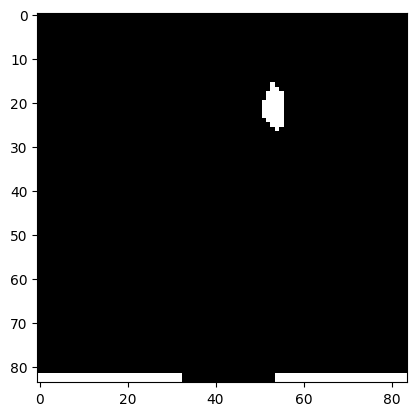

In [17]:
print(f'Process image')
plt.imshow(processed_frame[0], cmap='gray')

# 4. Visualize 4 stacked frame in state

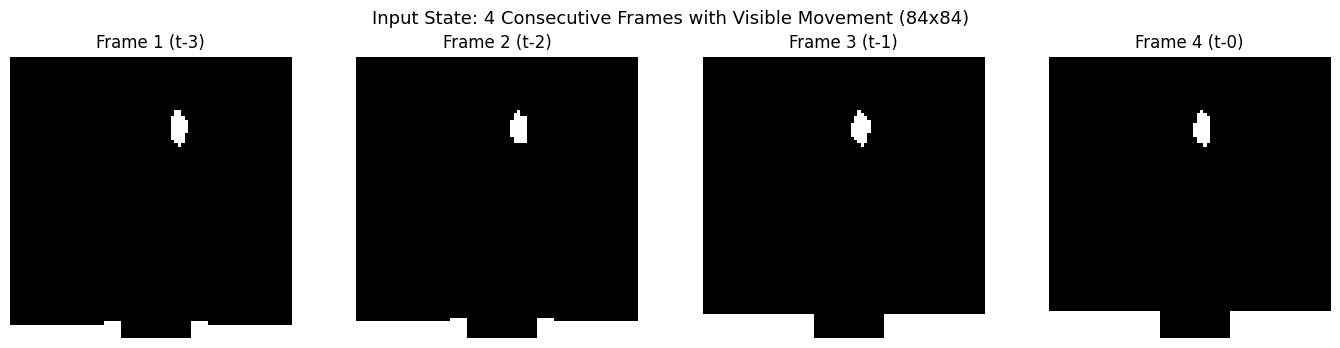

In [18]:
for step in range(4):
    # Action = 1 for the first frame (flap), then 0 (fall)
    current_action = 1 if step == 0 else 0
    next_raw, reward, terminal = game_state.next_frame(current_action)
    
    next_cropped = next_raw[:game_state.screen_width, :int(game_state.base_y)]
    next_processed = pre_processing(next_cropped, 84, 84)
    next_tensor = torch.from_numpy(next_processed)
    
    # Shift sliding window: discard oldest frame, push newest frame
    state = torch.cat((state[0, 1:, :, :], next_tensor))[None, :, :, :]

# Plot all 4 distinct frames side-by-side
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for i in range(4):
    frame_i = state[0, i, :, :].numpy()
    axes[i].imshow(frame_i, cmap='gray')
    axes[i].set_title(f"Frame {i+1} (t-{3-i})")
    axes[i].axis('off')

plt.suptitle("Input State: 4 Consecutive Frames with Visible Movement (84x84)", fontsize=13)
plt.tight_layout()
plt.show()

# 5. PPO Actor-Critic Network

In [19]:
from src.modern_rl import ActorCriticNetwork

# Initialize PPO Network
ppo_model = ActorCriticNetwork()
print("PPO ActorCriticNetwork initialized successfully!")

# Forward pass with current state
action_logits, state_value = ppo_model(state)
probs = torch.softmax(action_logits, dim=-1)

print("\n--- PPO Forward Pass Inspection ---")
print(f"Action Logits: {action_logits.detach().numpy()}")
print(f"Action Probabilities [p_idle, p_flap]: {probs.detach().numpy()}")
print(f"Critic Estimated Value V(s): {state_value.item():.4f}")

# Sample an action using get_action_and_value helper
action, log_prob, entropy, val = ppo_model.get_action_and_value(state)
print(f"\nSampled Action: {action.item()} (0=Idle, 1=Flap)")
print(f"Log-probability of sampled action: {log_prob.item():.4f}")
print(f"Distribution Entropy (exploration metric): {entropy.item():.4f}")

PPO ActorCriticNetwork initialized successfully!

--- PPO Forward Pass Inspection ---
Action Logits: [[  7.2711525 -21.510088 ]]
Action Probabilities [p_idle, p_flap]: [[1.0000000e+00 3.1656733e-13]]
Critic Estimated Value V(s): 37.4392

Sampled Action: 0 (0=Idle, 1=Flap)
Log-probability of sampled action: 0.0000
Distribution Entropy (exploration metric): 0.0000


In [20]:
ppo_total_params = sum(p.numel() for p in ppo_model.parameters() if p.requires_grad)
print("PPO Params", ppo_total_params)
print("\nPPO ActorCriticNetwork Architecture!")
ppo_model

PPO Params 1685667

PPO ActorCriticNetwork Architecture!


ActorCriticNetwork(
  (conv1): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (1): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
  )
  (fc_shared): Sequential(
    (0): Linear(in_features=3136, out_features=512, bias=True)
    (1): ReLU(inplace=True)
  )
  (actor_head): Linear(in_features=512, out_features=2, bias=True)
  (critic_head): Linear(in_features=512, out_features=1, bias=True)
)

# 6. GRPO Network

In [21]:
from src.modern_rl import ActorOnlyNetwork

# Initialize GRPO Network
grpo_model = ActorOnlyNetwork()
print("GRPO ActorOnlyNetwork initialized successfully!")

# Forward pass with current state
action_logits = grpo_model(state)
probs = torch.softmax(action_logits, dim=-1)

print("\n--- GRPO Forward Pass Inspection ---")
print(f"Action Logits: {action_logits.detach().numpy()}")
print(f"Action Probabilities [p_idle, p_flap]: {probs.detach().numpy()}")

# Sample an action using get_action helper
action, log_prob, entropy = grpo_model.get_action(state)
print(f"\nSampled Action: {action.item()} (0=Idle, 1=Flap)")
print(f"Log-probability of sampled action: {log_prob.item():.4f}")
print(f"Distribution Entropy: {entropy.item():.4f}")

GRPO ActorOnlyNetwork initialized successfully!

--- GRPO Forward Pass Inspection ---
Action Logits: [[-6.961176 54.53003 ]]
Action Probabilities [p_idle, p_flap]: [[1.9711047e-27 1.0000000e+00]]

Sampled Action: 1 (0=Idle, 1=Flap)
Log-probability of sampled action: 0.0000
Distribution Entropy: 0.0000


In [22]:
grpo_total_params = sum(p.numel() for p in grpo_model.parameters() if p.requires_grad)
print("GRPO Params", ppo_total_params)
print("\nGRPO ActorOnlyNetwork Architecture!")
grpo_model

GRPO Params 1685667

GRPO ActorOnlyNetwork Architecture!


ActorOnlyNetwork(
  (conv1): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (1): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
  )
  (fc_shared): Sequential(
    (0): Linear(in_features=3136, out_features=512, bias=True)
    (1): ReLU(inplace=True)
  )
  (actor_head): Linear(in_features=512, out_features=2, bias=True)
)

# 7. PPO and DPO Training

## 7.1 PPO Train function

In [28]:
def train_ppo_iteration(model, optimizer, game_state, current_state,
                        num_steps=128, gamma=0.99, gae_lambda=0.95,
                        clip_eps=0.2, ppo_epochs=4, batch_size=32,
                        c_val=0.5, c_ent=0.01):
    """
    Executes one full iteration of PPO on Flappy Bird.
    
    Args:
        model: ActorCriticNetwork
        optimizer: Adam optimizer
        game_state: FlappyBird environment instance
        current_state: Current 4-frame state tensor [1, 4, 84, 84]
        num_steps: Horizon length for one rollout buffer (e.g., 128 frames)
        gamma: Discount factor
        gae_lambda: GAE parameter balancing bias vs variance
        clip_eps: PPO clipping threshold (epsilon = 0.2 -> [0.8, 1.2])
        ppo_epochs: Number of optimization epochs over the collected buffer
        batch_size: Mini-batch size for SGD/Adam updates
        c_val: Value loss coefficient
        c_ent: Entropy bonus coefficient (encourages exploration)
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # --------------------------------------------------------------------------
    # PHASE 1: ROLLOUT COLLECTION (Agent interacts with environment)
    # --------------------------------------------------------------------------
    # Buffers to store experience trajectory
    b_states = []
    b_actions = []
    b_log_probs = []
    b_rewards = []
    b_dones = []
    b_values = []

    state = current_state.to(device)

    # Collect num_steps of transitions
    for step in range(num_steps):
        with torch.no_grad():
            # Get action, log_prob, and estimated value V(s) from current policy
            action, log_prob, _, value = model.get_action_and_value(state)

        # Step the environment
        raw_img, reward, terminal = game_state.next_frame(action.item())
        cropped = raw_img[:game_state.screen_width, :int(game_state.base_y)]
        processed = pre_processing(cropped, 84, 84)
        next_state = torch.cat((state[0, 1:, :, :], torch.from_numpy(processed).to(device)))[None, :, :, :]

        # Store transition into buffers
        b_states.append(state)
        b_actions.append(action)
        b_log_probs.append(log_prob)
        b_rewards.append(torch.tensor(reward, dtype=torch.float32, device=device))
        b_dones.append(torch.tensor(1.0 if terminal else 0.0, dtype=torch.float32, device=device))
        b_values.append(value)

        # Advance state
        state = next_state

    # Estimate value of the final state for GAE bootstrapping
    with torch.no_grad():
        _, _, _, next_val = model.get_action_and_value(state)

    # --------------------------------------------------------------------------
    # PHASE 2: GENERALIZED ADVANTAGE ESTIMATION (GAE Calculation)
    # Reference: Section 5.2 in 02_RLHF_and_PPO.md
    # --------------------------------------------------------------------------
    # Convert lists to stacked tensors: shape [num_steps]
    b_rewards_t = torch.stack(b_rewards).view(-1)
    b_dones_t = torch.stack(b_dones).view(-1)
    b_values_t = torch.stack(b_values).view(-1)
    next_val = next_val.view(-1)

    advantages = torch.zeros(num_steps, device=device)
    last_gae_lam = 0.0

    # Backwards loop from step T-1 down to 0
    for t in reversed(range(num_steps)):
        if t == num_steps - 1:
            next_non_terminal = 1.0 - b_dones_t[t]
            next_value = next_val[0]
        else:
            next_non_terminal = 1.0 - b_dones_t[t]
            next_value = b_values_t[t + 1]

        # 1-step TD Error: delta = r_t + gamma * V(s_{t+1}) - V(s_t)
        delta = b_rewards_t[t] + gamma * next_value * next_non_terminal - b_values_t[t]
        
        # Exponential discounted sum of TD errors
        advantages[t] = last_gae_lam = delta + gamma * gae_lambda * next_non_terminal * last_gae_lam

    # Target returns for Critic MSE training: Return = Advantage + Value (shape: [num_steps])
    b_returns = advantages + b_values_t

    # Flatten buffer tensors for mini-batch SGD
    flat_states = torch.cat(b_states, dim=0)          # [num_steps, 4, 84, 84]
    flat_actions = torch.stack(b_actions).view(-1)    # [num_steps]
    flat_old_log_probs = torch.stack(b_log_probs).view(-1) # [num_steps]
    flat_advantages = advantages.view(-1)             # [num_steps]
    flat_returns = b_returns.view(-1)                 # [num_steps]

    # Normalize Advantages (crucial for stable training)
    flat_advantages = (flat_advantages - flat_advantages.mean()) / (flat_advantages.std() + 1e-8)

    # --------------------------------------------------------------------------
    # PHASE 3 & 4: PPO CLIPPED SURROGATE UPDATE (Mini-batch Optimization)
    # Reference: Section 6 in 02_RLHF_and_PPO.md
    # --------------------------------------------------------------------------
    num_samples = num_steps
    indices = np.arange(num_samples)

    total_pg_loss = 0.0
    total_val_loss = 0.0

    for epoch in range(ppo_epochs):
        np.random.shuffle(indices)
        for start in range(0, num_samples, batch_size):
            end = start + batch_size
            mb_idx = indices[start:end]

            # Re-evaluate actions and values with CURRENT policy weights
            _, new_log_prob, entropy, new_value = model.get_action_and_value(
                flat_states[mb_idx], flat_actions[mb_idx]
            )

            # 1. Probability Ratio: r_t(theta) = exp(new_log_prob - old_log_prob)
            log_ratio = new_log_prob - flat_old_log_probs[mb_idx]
            ratio = torch.exp(log_ratio)

            # 2. PPO Clipped Policy Loss
            mb_adv = flat_advantages[mb_idx]
            surr1 = ratio * mb_adv
            surr2 = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps) * mb_adv
            policy_loss = -torch.min(surr1, surr2).mean()

            # 3. Critic Value Loss (MSE) - ensure shape matching [batch_size]
            value_loss = 0.5 * ((new_value.view(-1) - flat_returns[mb_idx].view(-1)) ** 2).mean()

            # 4. Entropy Bonus (Encourages exploration)
            entropy_loss = -entropy.mean()

            # Combined Objective
            loss = policy_loss + c_val * value_loss + c_ent * entropy_loss

            # Gradient Step
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
            optimizer.step()

            total_pg_loss += policy_loss.item()
            total_val_loss += value_loss.item()

    avg_pg_loss = total_pg_loss / (ppo_epochs * (num_samples // batch_size))
    avg_val_loss = total_val_loss / (ppo_epochs * (num_samples // batch_size))

    return state, avg_pg_loss, avg_val_loss, b_rewards_t.sum().item()

In [30]:
# Initialize test setup for 1 PPO iteration
from torch import nn
ppo_agent = ActorCriticNetwork()
ppo_optimizer = torch.optim.Adam(ppo_agent.parameters(), lr=1e-4)

# Execute 1 training iteration (128 frames of experience)
print("\n--- Running 1 Iteration of PPO Training (128 steps) ---")
state, pg_loss, val_loss, total_rew = train_ppo_iteration(
    ppo_agent, ppo_optimizer, game_state, state, num_steps=128
)

print(f"PPO Iteration Completed!")
print(f"Policy Loss: {pg_loss:.4f}")
print(f"Value Loss (Critic): {val_loss:.4f}")
print(f"Total Trajectory Reward: {total_rew:.2f}")


--- Running 1 Iteration of PPO Training (128 steps) ---
PPO Iteration Completed!
Policy Loss: 0.0059
Value Loss (Critic): 1502.2128
Total Trajectory Reward: 10.60


## 7.2 DPO Training Function

In [ ]:
def run_single_episode(model, max_steps=128):
    """
    Helper function: Plays 1 full episode of Flappy Bird until game over or max_steps.
    Returns:
        states: Tensor [T, 4, 84, 84]
        actions: Tensor [T]
        old_log_probs: Tensor [T]
        total_reward: float scalar
    """
    device = next(model.parameters()).device
    env = FlappyBird()
    raw_img, _, _ = env.next_frame(0)
    cropped = raw_img[:env.screen_width, :int(env.base_y)]
    processed = pre_processing(cropped, 84, 84)
    frame_tensor = torch.from_numpy(processed).to(device)
    state = torch.cat(tuple(frame_tensor for _ in range(4)))[None, :, :, :]

    ep_states = []
    ep_actions = []
    ep_log_probs = []
    total_reward = 0.0

    for _ in range(max_steps):
        with torch.no_grad():
            action, log_prob, _ = model.get_action(state)

        next_raw, reward, terminal = env.next_frame(action.item())
        next_cropped = next_raw[:env.screen_width, :int(env.base_y)]
        next_processed = pre_processing(next_cropped, 84, 84)
        next_state = torch.cat((state[0, 1:, :, :], torch.from_numpy(next_processed).to(device)))[None, :, :, :]

        ep_states.append(state)
        ep_actions.append(action)
        ep_log_probs.append(log_prob)
        total_reward += reward

        state = next_state
        if terminal:
            break

    return (
        torch.cat(ep_states, dim=0),
        torch.stack(ep_actions),
        torch.stack(ep_log_probs),
        total_reward
    )


def train_grpo_iteration(model, optimizer, group_size=4, clip_eps=0.2,
                         grpo_epochs=4, batch_size=32, c_ent=0.01):
    """
    Executes one full iteration of GRPO on Flappy Bird.
    """
    device = next(model.parameters()).device
    model.train()

    # --------------------------------------------------------------------------
    # PHASE 1: GROUP ROLLOUT (Sample G independent episodes)
    # --------------------------------------------------------------------------
    group_trajectories = []
    group_rewards = []

    for _ in range(group_size):
        states, actions, log_probs, ep_reward = run_single_episode(model)
        group_trajectories.append({
            "states": states,
            "actions": actions,
            "old_log_probs": log_probs,
            "reward": ep_reward
        })
        group_rewards.append(ep_reward)

    # --------------------------------------------------------------------------
    # PHASE 2: GROUP ADVANTAGE (Calculate group statistics mu and sigma)
    # Reference: Section 3.1 in 04_GRPO_and_Reasoning.md: A_i = (R_i - mu) / sigma
    # --------------------------------------------------------------------------
    r_tensor = torch.tensor(group_rewards, dtype=torch.float32, device=device)
    mean_r = r_tensor.mean()
    std_r = r_tensor.std() + 1e-8

    # Calculate scalar advantage for each episode in the group
    group_advantages = (r_tensor - mean_r) / std_r

    # --------------------------------------------------------------------------
    # PHASE 3: FLATTEN EXPERIENCES FOR TRAINING
    # --------------------------------------------------------------------------
    all_states = []
    all_actions = []
    all_old_log_probs = []
    all_advantages = []

    for i, traj in enumerate(group_trajectories):
        T = traj["actions"].shape[0]
        adv_i = group_advantages[i]  # Scalar advantage broadcast to all tokens in episode i
        all_states.append(traj["states"])
        all_actions.append(traj["actions"])
        all_old_log_probs.append(traj["old_log_probs"])
        all_advantages.append(torch.full((T,), adv_i.item(), device=device))

    flat_states = torch.cat(all_states, dim=0)
    flat_actions = torch.cat(all_actions, dim=0)
    flat_old_log_probs = torch.cat(all_old_log_probs, dim=0)
    flat_advantages = torch.cat(all_advantages, dim=0)

    # --------------------------------------------------------------------------
    # PHASE 4: GRPO CLIPPED UPDATE (Notice: NO CRITIC LOSS!)
    # --------------------------------------------------------------------------
    num_samples = flat_states.shape[0]
    indices = np.arange(num_samples)
    total_policy_loss = 0.0

    for epoch in range(grpo_epochs):
        np.random.shuffle(indices)
        for start in range(0, num_samples, batch_size):
            end = start + batch_size
            mb_idx = indices[start:end]

            # Re-evaluate with CURRENT policy weights
            _, new_log_prob, entropy = model.get_action(
                flat_states[mb_idx], flat_actions[mb_idx]
            )

            # 1. Ratio: r_t(theta) = exp(new_log_prob - old_log_prob)
            ratio = torch.exp(new_log_prob - flat_old_log_probs[mb_idx])

            # 2. Clipped Surrogate Objective
            mb_adv = flat_advantages[mb_idx]
            surr1 = ratio * mb_adv
            surr2 = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps) * mb_adv
            policy_loss = -torch.min(surr1, surr2).mean()

            # 3. Entropy Bonus
            entropy_loss = -entropy.mean()

            # Combined Loss: ONLY Policy + Entropy (Zero Value Loss!)
            loss = policy_loss + c_ent * entropy_loss

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
            optimizer.step()

            total_policy_loss += policy_loss.item()

    avg_loss = total_policy_loss / (grpo_epochs * max(1, num_samples // batch_size))
    return avg_loss, group_rewards

In [32]:
# Test 1 GRPO iteration
grpo_agent = ActorOnlyNetwork()
grpo_optimizer = torch.optim.Adam(grpo_agent.parameters(), lr=1e-4)

print("\n--- Running 1 Iteration of GRPO Training (Group Size = 4) ---")
grpo_loss, ep_rewards = train_grpo_iteration(grpo_agent, grpo_optimizer, group_size=4)
print(f"GRPO Iteration Completed!")
print(f"Policy Loss: {grpo_loss:.4f}")
print(f"Group Rewards of 4 Birds: {ep_rewards} (Mean: {np.mean(ep_rewards):.2f})")


--- Running 1 Iteration of GRPO Training (Group Size = 4) ---
GRPO Iteration Completed!
Policy Loss: 0.0000
Group Rewards of 4 Birds: [0.7000000000000004, 0.7000000000000004, 0.7000000000000004, 0.7000000000000004] (Mean: 0.70)


# 8. Training Loop

In [ ]:
def run_benchmark(algorithm="PPO", num_iterations=10):
    """
    Executes multiple iterations of training and logs progression.
    Args:
        algorithm: "PPO" or "GRPO"
        num_iterations: Number of outer loop iterations
    """
    print(f"\n=======================================================")
    print(f"  STARTING OUTER TRAINING LOOP BENCHMARK: {algorithm}")
    print(f"=======================================================")

    history_rewards = []
    history_losses = []

    if algorithm == "PPO":
        agent = ActorCriticNetwork()
        optimizer = torch.optim.Adam(agent.parameters(), lr=1e-4)
        env = FlappyBird()
        # Initialize starting state
        img, _, _ = env.next_frame(0)
        crop = img[:env.screen_width, :int(env.base_y)]
        proc = pre_processing(crop, 84, 84)
        curr_state = torch.cat(tuple(torch.from_numpy(proc) for _ in range(4)))[None, :, :, :]

        for it in range(num_iterations):
            curr_state, p_loss, v_loss, tot_rew = train_ppo_iteration(
                agent, optimizer, env, curr_state, num_steps=128
            )
            history_rewards.append(tot_rew)
            history_losses.append(p_loss)
            print(f"Iteration [{it+1:02d}/{num_iterations:02d}] | Reward: {tot_rew:6.2f} | Policy Loss: {p_loss:6.4f} | Value Loss: {v_loss:6.4f}")

    elif algorithm == "GRPO":
        agent = ActorOnlyNetwork()
        optimizer = torch.optim.Adam(agent.parameters(), lr=1e-4)

        for it in range(num_iterations):
            loss, rewards = train_grpo_iteration(agent, optimizer, group_size=4)
            mean_rew = float(np.mean(rewards))
            history_rewards.append(mean_rew)
            history_losses.append(loss)
            print(f"Iteration [{it+1:02d}/{num_iterations:02d}] | Group Mean Reward: {mean_rew:6.2f} | Policy Loss: {loss:6.4f} | Rewards: {[round(r, 1) for r in rewards]}")

    return history_rewards, history_losses

: 

In [ ]:
# Run a quick 3-iteration demonstration for both algorithms
ppo_rewards, _ = run_benchmark(algorithm="PPO", num_iterations=3)
grpo_rewards, _ = run_benchmark(algorithm="GRPO", num_iterations=3)

print("\nAll Benchmark Iterations Completed Successfully!")